In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import inspect

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_sample_weight

In [3]:
df = pd.read_excel('glass.xlsx', sheet_name='glass')
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [4]:
df.shape

(214, 10)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [6]:
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


In [7]:
df.isnull().sum()

RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

In [8]:
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Dataset shape after removing duplicates:', df.shape)

Duplicate rows: 1
Dataset shape after removing duplicates: (213, 10)


In [9]:
df['Type'].value_counts().sort_index()

Type
1    69
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64

The target has six classes: 1, 2, 3, 5, 6 and 7. Type 4 is not present in this dataset. The class counts are not equal, so I will use stratified splitting and class weights when training the models.

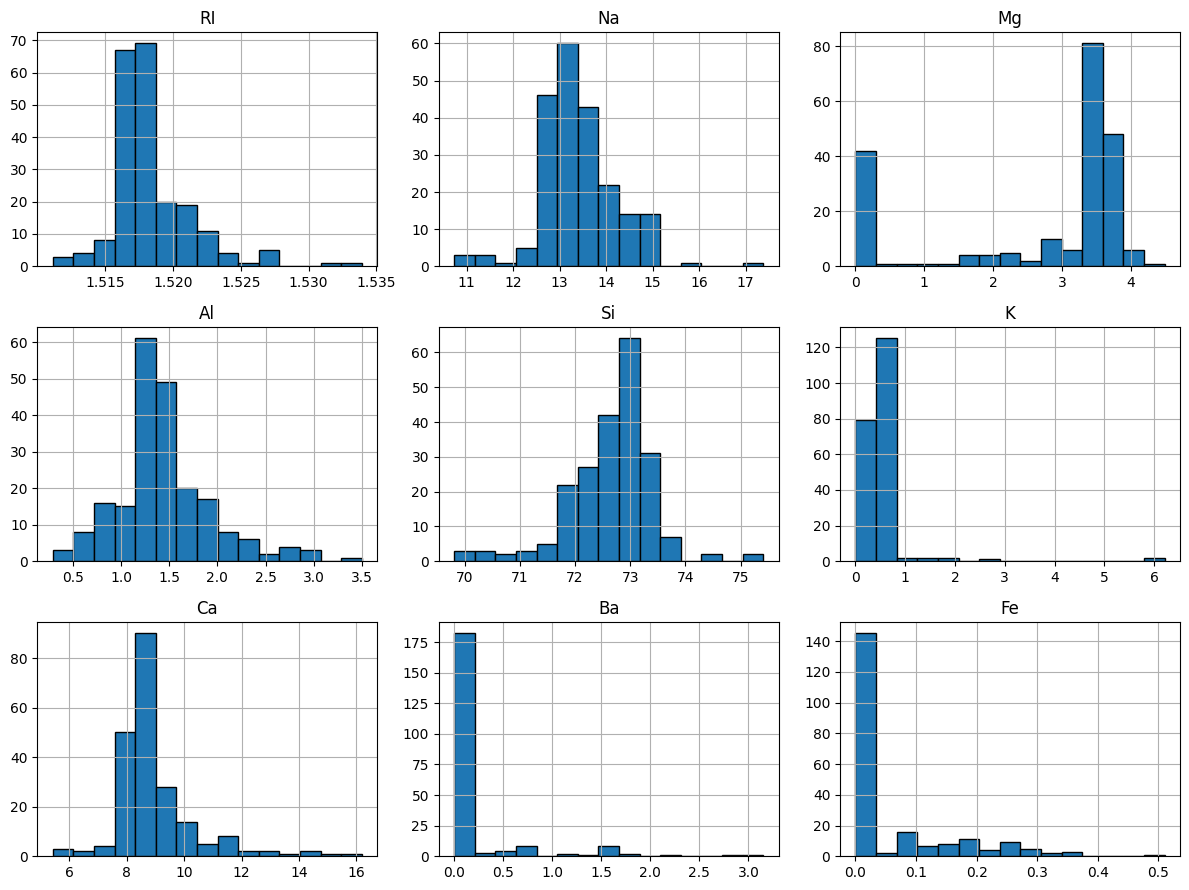

In [10]:
df.drop(columns='Type').hist(figsize=(12, 9), bins=15, edgecolor='black')
plt.tight_layout()
plt.show()

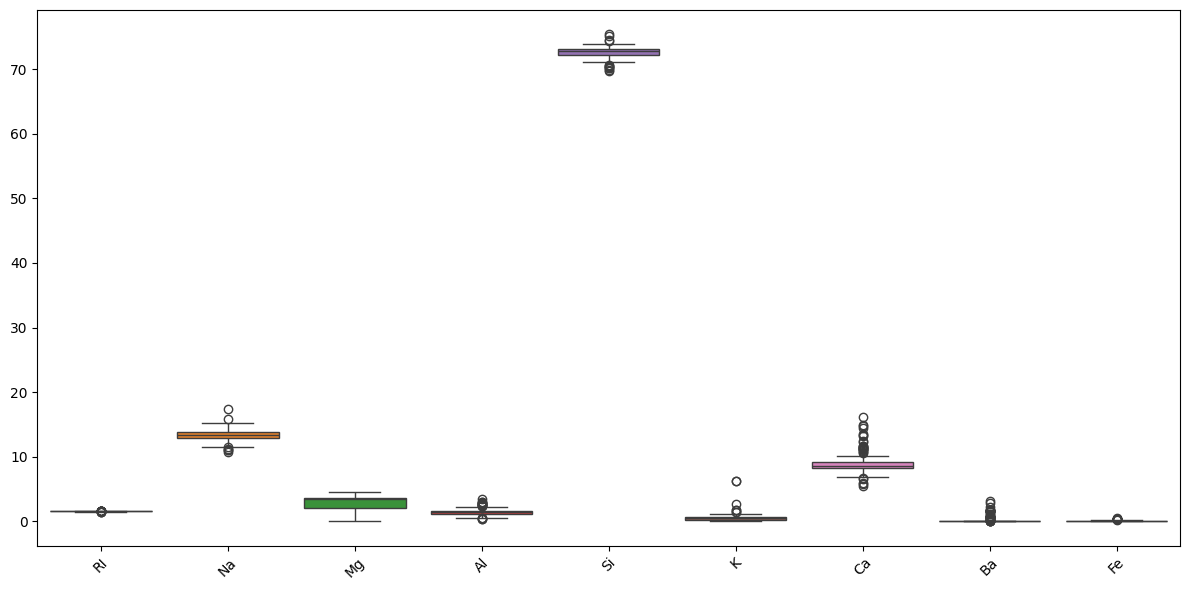

In [11]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df.drop(columns='Type'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

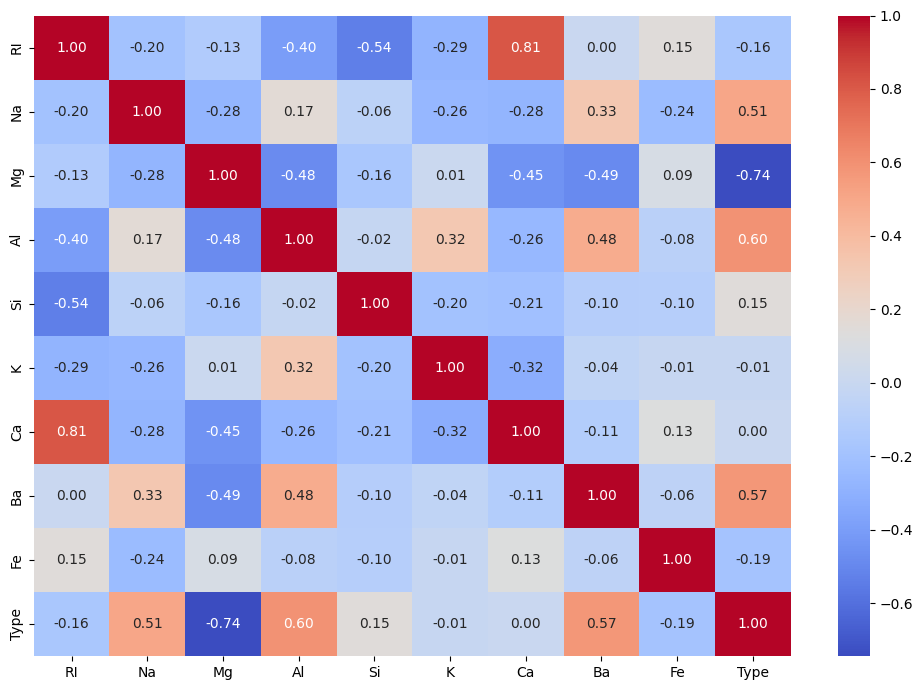

In [12]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.tight_layout()
plt.show()

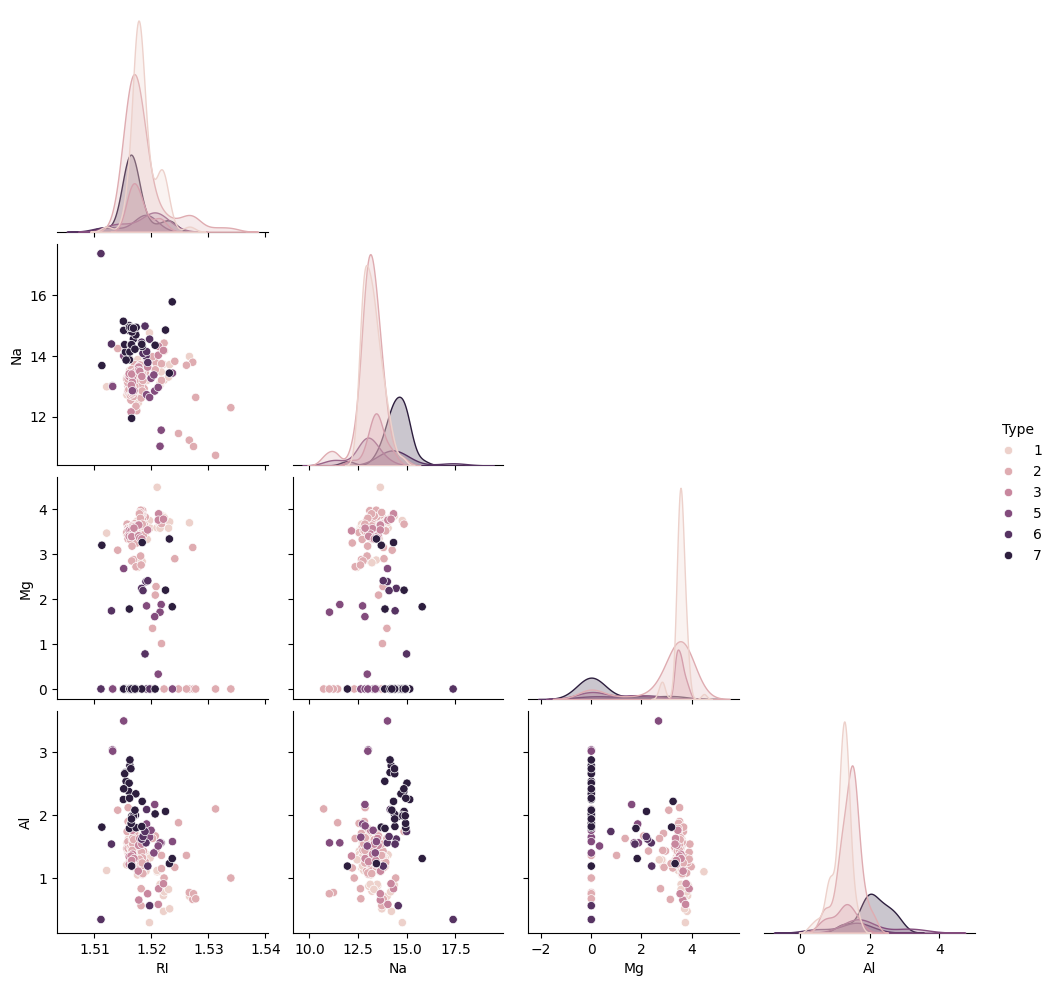

In [13]:
sns.pairplot(df[['RI', 'Na', 'Mg', 'Al', 'Type']], hue='Type', corner=True)
plt.show()

In [14]:
outlier_counts = {}
for column in df.drop(columns='Type').columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_counts[column] = ((df[column] < lower) | (df[column] > upper)).sum()

pd.Series(outlier_counts, name='Possible outliers').sort_values(ascending=False)

Ba    38
Ca    27
RI    17
Al    17
Si    12
Fe    12
Na     7
K      7
Mg     0
Name: Possible outliers, dtype: int64

Some box plots show possible outliers. These values are kept because they may represent real glass compositions, and tree models can work with outliers without requiring them to be removed. There are no missing values in the supplied data. The duplicate row was removed.

In [15]:
X = df.drop(columns='Type')
y = df['Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training rows:', X_train.shape[0])
print('Testing rows:', X_test.shape[0])

Training rows: 170
Testing rows: 43


In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

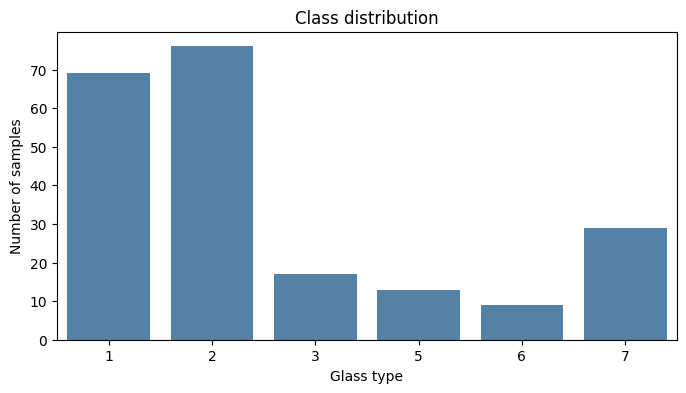

In [17]:
plt.figure(figsize=(8, 4))
sns.countplot(x=y, color='steelblue')
plt.xlabel('Glass type')
plt.ylabel('Number of samples')
plt.title('Class distribution')
plt.show()

In [18]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42
)

rf_model.fit(X_train_scaled, y_train)
rf_pred = rf_model.predict(X_test_scaled)

print(classification_report(y_test, rf_pred, zero_division=0))

              precision    recall  f1-score   support

           1       0.75      0.86      0.80        14
           2       0.73      0.73      0.73        15
           3       1.00      0.67      0.80         3
           5       1.00      0.67      0.80         3
           6       0.67      1.00      0.80         2
           7       1.00      0.83      0.91         6

    accuracy                           0.79        43
   macro avg       0.86      0.79      0.81        43
weighted avg       0.81      0.79      0.79        43



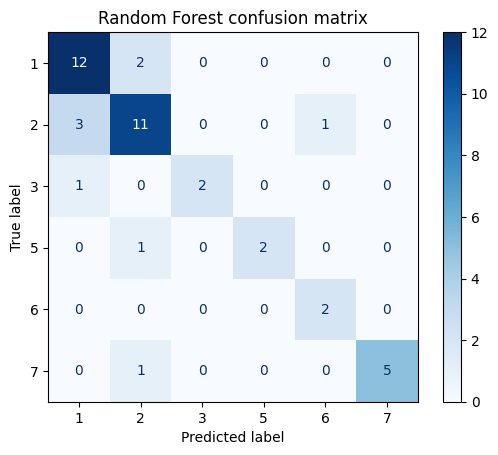

In [19]:
ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, cmap='Blues')
plt.title('Random Forest confusion matrix')
plt.show()

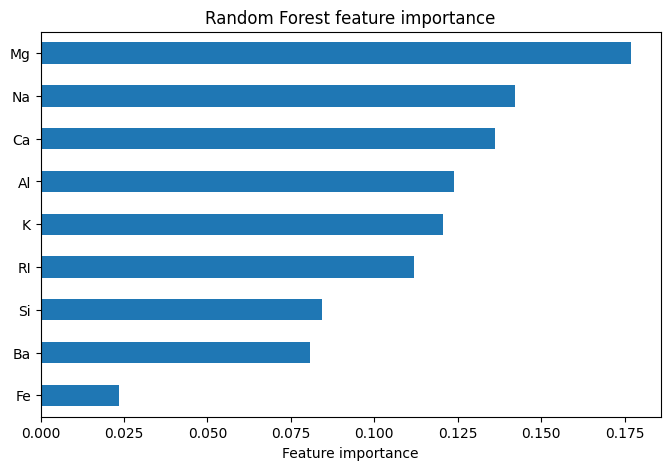

In [20]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
importances.plot(kind='barh', figsize=(8, 5))
plt.xlabel('Feature importance')
plt.title('Random Forest feature importance')
plt.show()

In [21]:
bagging_parameter = 'estimator' if 'estimator' in inspect.signature(BaggingClassifier).parameters else 'base_estimator'
bagging_model = BaggingClassifier(
    **{bagging_parameter: DecisionTreeClassifier(class_weight='balanced', random_state=42)},
    n_estimators=100,
    random_state=42
)

bagging_model.fit(X_train_scaled, y_train)
bagging_pred = bagging_model.predict(X_test_scaled)
print(classification_report(y_test, bagging_pred, zero_division=0))

              precision    recall  f1-score   support

           1       0.75      0.86      0.80        14
           2       0.71      0.67      0.69        15
           3       1.00      0.67      0.80         3
           5       0.67      0.67      0.67         3
           6       0.67      1.00      0.80         2
           7       1.00      0.83      0.91         6

    accuracy                           0.77        43
   macro avg       0.80      0.78      0.78        43
weighted avg       0.78      0.77      0.77        43



In [22]:
boosting_parameter = 'estimator' if 'estimator' in inspect.signature(AdaBoostClassifier).parameters else 'base_estimator'
boosting_model = AdaBoostClassifier(
    **{boosting_parameter: DecisionTreeClassifier(max_depth=1, random_state=42)},
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

initial_weights = compute_sample_weight(class_weight='balanced', y=y_train)
boosting_model.fit(X_train_scaled, y_train, sample_weight=initial_weights)
boosting_pred = boosting_model.predict(X_test_scaled)
print(classification_report(y_test, boosting_pred, zero_division=0))

              precision    recall  f1-score   support

           1       0.00      0.00      0.00        14
           2       0.53      0.53      0.53        15
           3       0.07      0.33      0.12         3
           5       0.30      1.00      0.46         3
           6       0.00      0.00      0.00         2
           7       1.00      0.67      0.80         6

    accuracy                           0.37        43
   macro avg       0.32      0.42      0.32        43
weighted avg       0.35      0.37      0.34        43



In [23]:
models = {
    'Random Forest': rf_pred,
    'Bagging': bagging_pred,
    'AdaBoost': boosting_pred
}

results = []
for name, predictions in models.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision (macro)': precision_score(y_test, predictions, average='macro', zero_division=0),
        'Recall (macro)': recall_score(y_test, predictions, average='macro', zero_division=0),
        'F1-score (macro)': f1_score(y_test, predictions, average='macro', zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values('F1-score (macro)', ascending=False)
results_df

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Random Forest,0.790698,0.858333,0.792857,0.807071
1,Bagging,0.767442,0.799603,0.781746,0.777569
2,AdaBoost,0.372093,0.317460,0.422222,0.318753


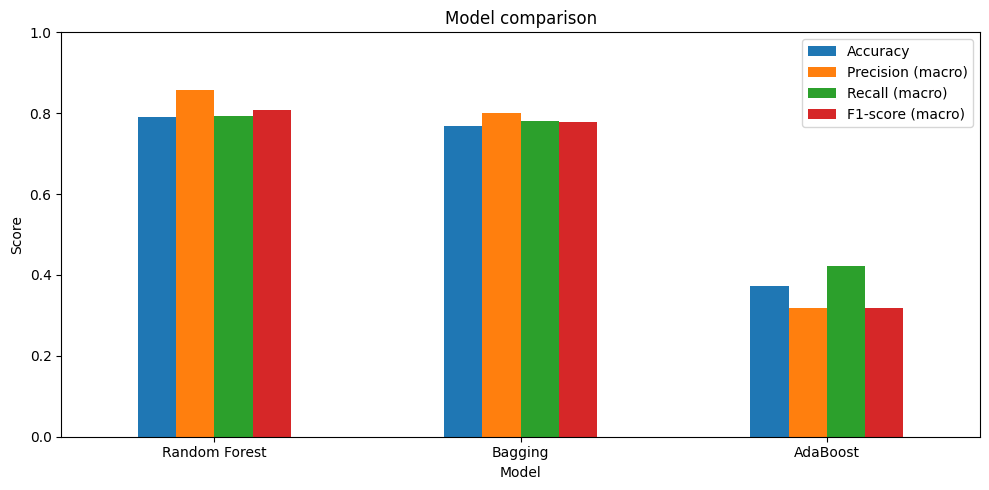

In [24]:
results_df.set_index('Model')[['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1-score (macro)']].plot(kind='bar', figsize=(10, 5), ylim=(0, 1))
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.title('Model comparison')
plt.tight_layout()
plt.show()